In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the data

In [2]:
df=pd.read_csv("cars_data.csv")
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,NaN,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0


# Requirements

In [3]:
df.shape

(1000, 8)

In [4]:
df.describe()

,Year,Mileage,Engine_Size,Price
count,974.000000,979.000000,964.000000,987.000000
mean,2016.320329,104185.955056,2.490560,8473.716312
std,4.050561,56333.931315,0.866082,6301.920977
min,2010.000000,5207.000000,1.000000,3000.000000
25%,2013.000000,54002.500000,1.800000,4068.000000
50%,2016.000000,104853.000000,2.500000,6426.000000
75%,2020.000000,155030.000000,3.200000,10917.000000
max,2023.000000,199812.000000,4.000000,43994.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            979 non-null    str    
 1   Year             974 non-null    float64
 2   Mileage          979 non-null    float64
 3   Engine_Size      964 non-null    float64
 4   Fuel_Type        982 non-null    str    
 5   Transmission     962 non-null    str    
 6   Previous_Owners  950 non-null    str    
 7   Price            987 non-null    float64
dtypes: float64(4), str(4)
memory usage: 82.6 KB


In [6]:
df.isnull().sum().sort_values(ascending=False)

Previous_Owners    50
Transmission       38
Engine_Size        36
Year               26
Mileage            21
Brand              21
Fuel_Type          18
Price              13
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

# Filling the missing value

<Axes: ylabel='Frequency'>

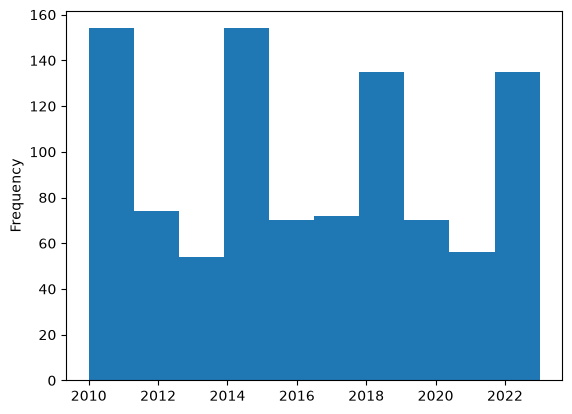

In [8]:
df['Year'].plot(kind='hist')

In [9]:
df['Year'].skew()

np.float64(0.04591240474388786)

<Axes: ylabel='Frequency'>

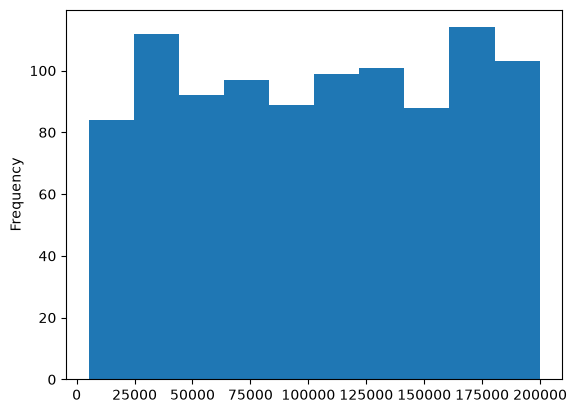

In [10]:
df['Mileage'].plot(kind='hist')

In [11]:
df['Mileage'].skew()

np.float64(-0.027299309759483685)

<Axes: ylabel='Frequency'>

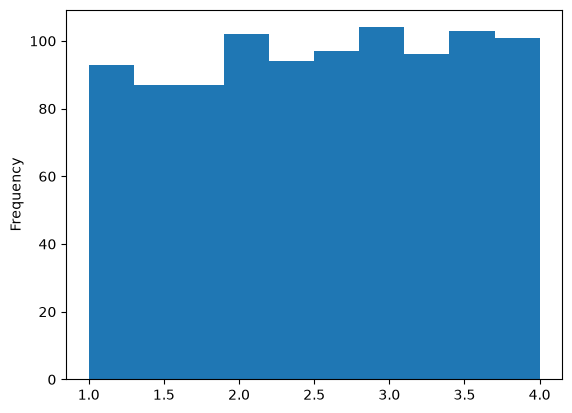

In [12]:
df['Engine_Size'].plot(kind='hist')

In [13]:
df['Engine_Size'].skew()

np.float64(-0.023705750041610855)

<Axes: ylabel='Frequency'>

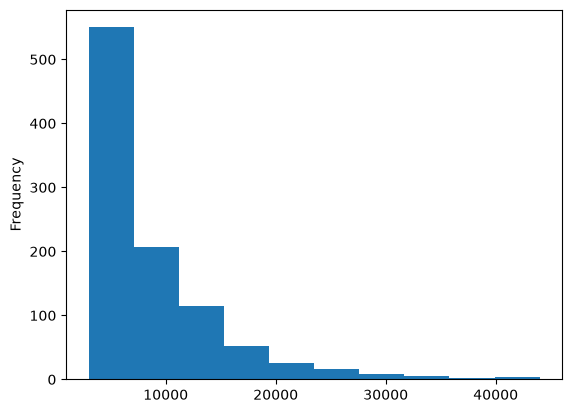

In [14]:
df['Price'].plot(kind='hist')

In [15]:
df['Price'].skew()

np.float64(2.11213671582442)

In [16]:
display(df['Previous_Owners'].unique())

<ArrowStringArray>
['2', '5', '1', nan, ' ', '3', '4']
Length: 7, dtype: str

In [17]:
df['Previous_Owners'].unique()

<ArrowStringArray>
['2', '5', '1', nan, ' ', '3', '4']
Length: 7, dtype: str

In [18]:
df['Previous_Owners']=df['Previous_Owners'].replace(
    " ", np.nan, regex=True   
)


In [19]:
col=['Engine_Size','Mileage','Year']

In [20]:
from sklearn.impute import SimpleImputer 
imputer= SimpleImputer(missing_values=np.nan,strategy='mean')
for i in col:
    df[i]=imputer.fit_transform(df[[i]])


In [21]:
obj=['Previous_Owners','Brand','Fuel_Type','Transmission']

In [22]:
imputer= SimpleImputer(missing_values=np.nan,strategy='most_frequent')
for co in obj:
    df[[co]]=imputer.fit_transform(df[[co]])


In [23]:
imputer= SimpleImputer(missing_values=np.nan,strategy='median')
df[['Price']]=imputer.fit_transform(df[['Price']])

In [24]:
df.isnull().sum().sort_values(ascending=False)

Brand              0
Year               0
Mileage            0
Engine_Size        0
Fuel_Type          0
Transmission       0
Previous_Owners    0
Price              0
dtype: int64

# Visualization

<Axes: xlabel='Transmission', ylabel='count'>

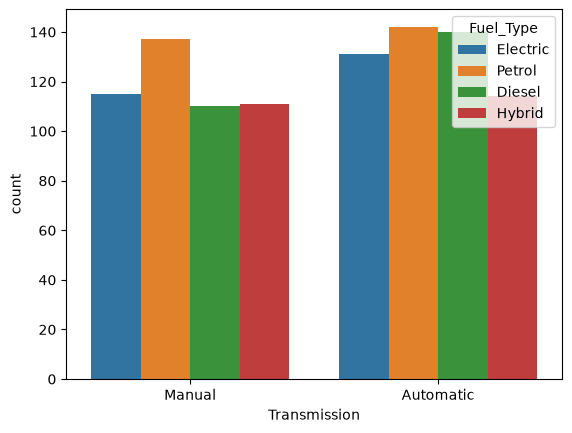

In [25]:
sns.countplot(x=df['Transmission'],hue=df['Fuel_Type'])

<Axes: xlabel='Mileage', ylabel='Price'>

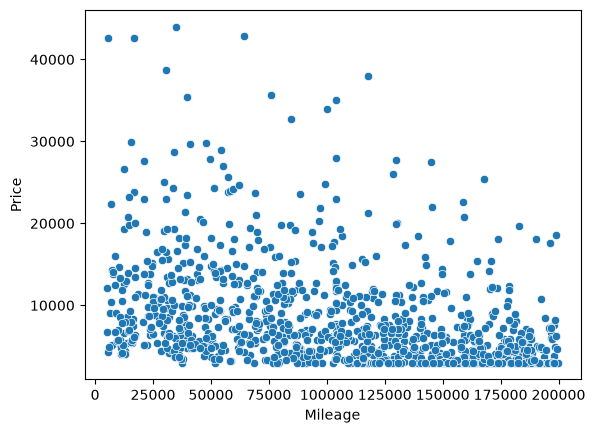

In [26]:
sns.scatterplot(data=df,x='Mileage',y='Price')

<Axes: xlabel='Engine_Size', ylabel='Price'>

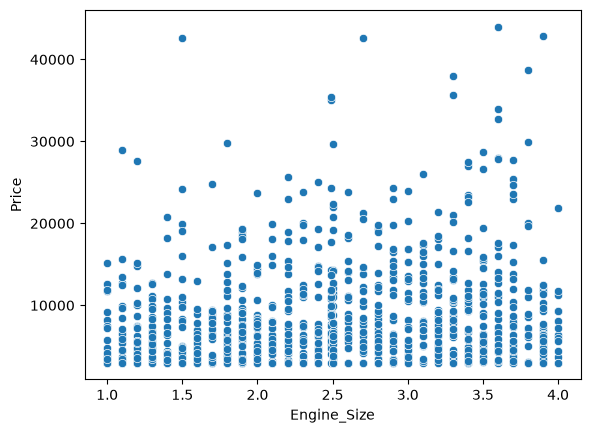

In [27]:
sns.scatterplot(data=df,x='Engine_Size',y='Price')

<Axes: xlabel='Previous_Owners', ylabel='Price'>

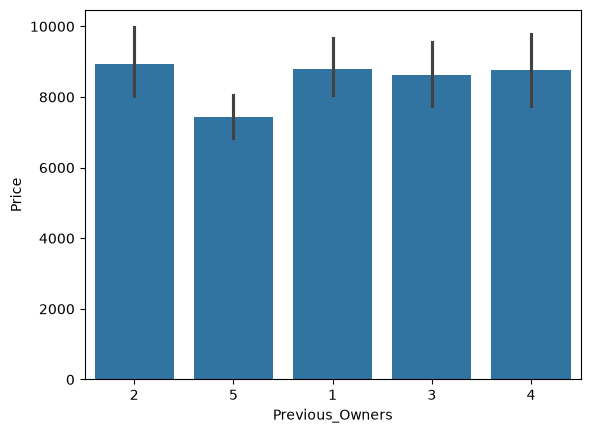

In [28]:
sns.barplot(data=df,x='Previous_Owners',y='Price')

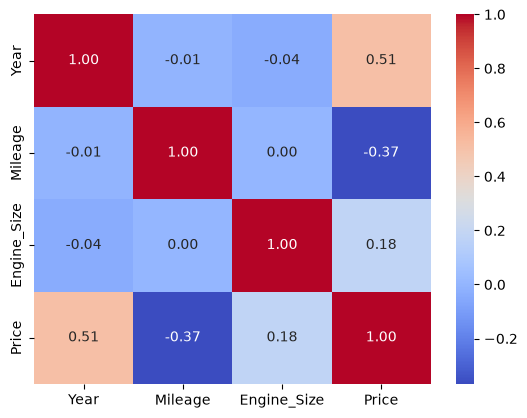

In [29]:
num_df = df.select_dtypes(
    include="number"
)

sns.heatmap(
    num_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()

# Encoding, Scaling, Outliiers, & train test split

In [30]:
"""
convert the previous owners columns into folat or int
"""

df['Previous_Owners']=df['Previous_Owners'].astype(float)

In [31]:
df.select_dtypes(object).columns

C:\Users\abdoa\AppData\Local\Temp\ipykernel_8188\1734617840.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(object).columns


Index(['Brand', 'Fuel_Type', 'Transmission'], dtype='str')

In [32]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
ohe=OneHotEncoder(sparse_output=False,
                  handle_unknown='ignore',
                  drop='first'
                                    ).set_output(transform='pandas')

In [33]:
df['Transmission'].nunique()

2

In [34]:
col=['Fuel_Type','Transmission']

In [35]:
for i in col:
    temp=ohe.fit_transform(df[[i]])
    df=pd.concat([df,temp],axis=1)

In [36]:
le=LabelEncoder()

In [37]:
df['Brand']=le.fit_transform(df[['Brand']])

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [38]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Manual
0,3,2015.0,110373.0,2.5,Electric,Manual,2.0,3000.0,1.0,0.0,0.0,1.0
1,5,2010.0,186144.0,1.3,Electric,Manual,5.0,4844.0,1.0,0.0,0.0,1.0
2,6,2018.0,29574.0,2.6,Petrol,Manual,1.0,6628.0,0.0,0.0,1.0,1.0
3,3,2010.0,139502.0,2.4,Diesel,Automatic,5.0,3000.0,0.0,0.0,0.0,0.0
4,0,2014.0,148748.0,3.5,Diesel,Manual,1.0,6451.0,0.0,0.0,0.0,1.0


In [39]:
df.drop(['Fuel_Type','Transmission'],axis=1, inplace=True)

In [40]:
df.reset_index(drop=True, inplace=True)

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Brand                1000 non-null   int64  
 1   Year                 1000 non-null   float64
 2   Mileage              1000 non-null   float64
 3   Engine_Size          1000 non-null   float64
 4   Previous_Owners      1000 non-null   float64
 5   Price                1000 non-null   float64
 6   Fuel_Type_Electric   1000 non-null   float64
 7   Fuel_Type_Hybrid     1000 non-null   float64
 8   Fuel_Type_Petrol     1000 non-null   float64
 9   Transmission_Manual  1000 non-null   float64
dtypes: float64(9), int64(1)
memory usage: 78.3 KB


In [42]:
df.isnull().sum().sort_values(ascending=False)

Brand                  0
Year                   0
Mileage                0
Engine_Size            0
Previous_Owners        0
Price                  0
Fuel_Type_Electric     0
Fuel_Type_Hybrid       0
Fuel_Type_Petrol       0
Transmission_Manual    0
dtype: int64

<Axes: ylabel='Price'>

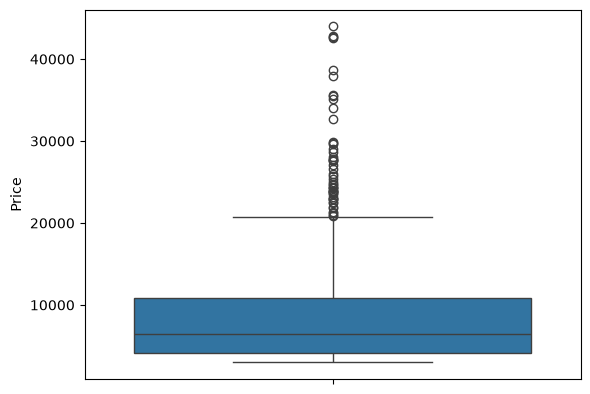

In [43]:
sns.boxplot(df['Price'])

In [44]:

def remove_outliers_iqr(data, column_name="value"):
    """
    Removes outliers using the IQR method.
    Returns filtered DataFrame.
    """
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column_name] >= lower) & (df[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(df, column_name=['Price'])

print(df.shape,cleaned_df.shape)

(1000, 10) (1000, 10)


In [45]:
X=df.drop(['Price'],axis=1)

In [46]:
y=df['Price']

In [47]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,
                                   test_size= 0.20, random_state=42)

In [48]:
from sklearn.preprocessing import StandardScaler

In [49]:
scal=StandardScaler()

In [50]:
X_train[['Year','Mileage']] = scal.fit_transform(
    X_train[['Year','Mileage']]
)

X_test[['Year','Mileage']] = scal.transform(
    X_test[['Year','Mileage']]
)

In [51]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error , mean_squared_error,root_mean_squared_error,r2_score

In [52]:
model=KNeighborsRegressor(n_neighbors=5,p=1,metric='minkowski')

In [53]:
model.fit(X_train,y_train)

,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'ma...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [54]:
y_prd=model.predict(X_test)

In [55]:
MSE=mean_absolute_error(y_test,y_prd)
print(MSE)

2225.119


In [56]:
MAE=mean_absolute_error(y_test,y_prd)
print(MAE)

2225.119


In [57]:
RMSE=root_mean_squared_error(y_test,y_prd)
print(RMSE)

3800.636910492766


In [58]:
r2=r2_score(y_test,y_prd)
print(r2)

0.6365301362210103


In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
#from catboost import CatBoostRegressor
import lightgbm as lgb
from lightgbm import LGBMRegressor

In [62]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    #"CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [63]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/14 [00:00<?, ?it/s]

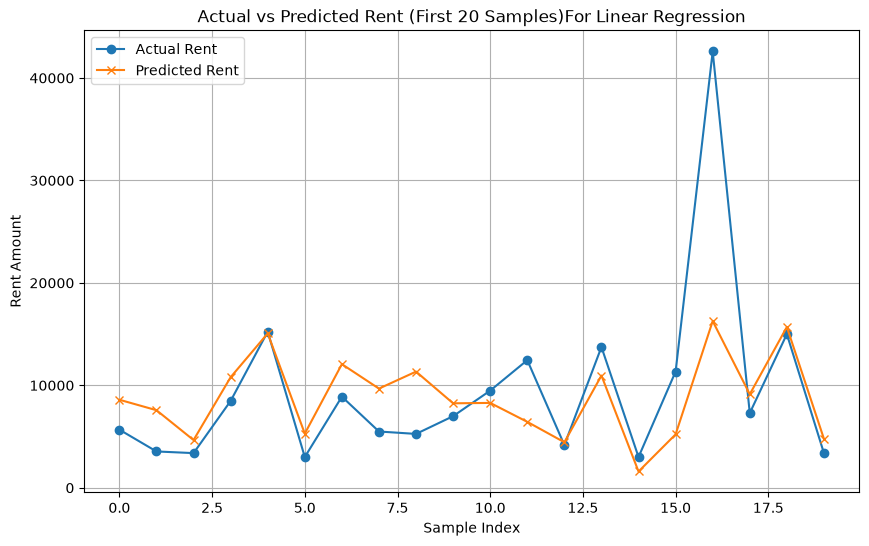

  7%|▋         | 1/14 [00:00<00:02,  5.31it/s]

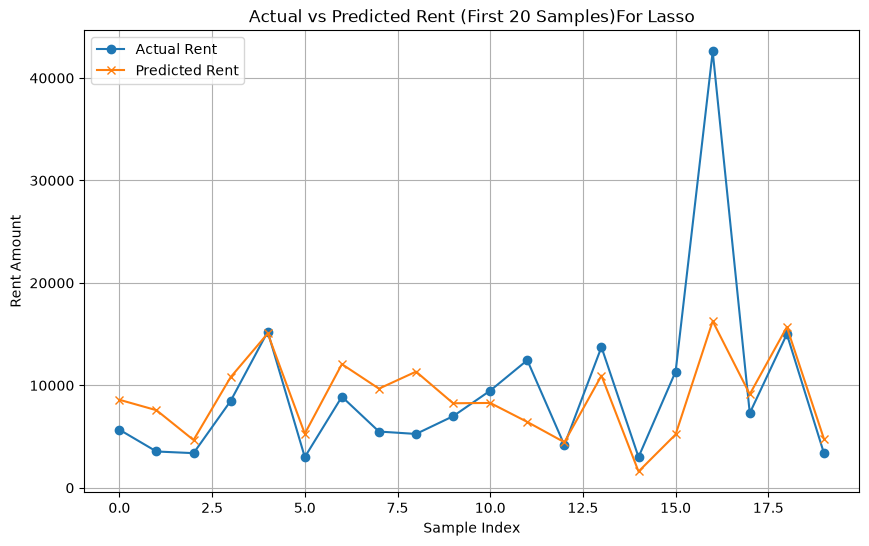

 14%|█▍        | 2/14 [00:00<00:02,  4.29it/s]

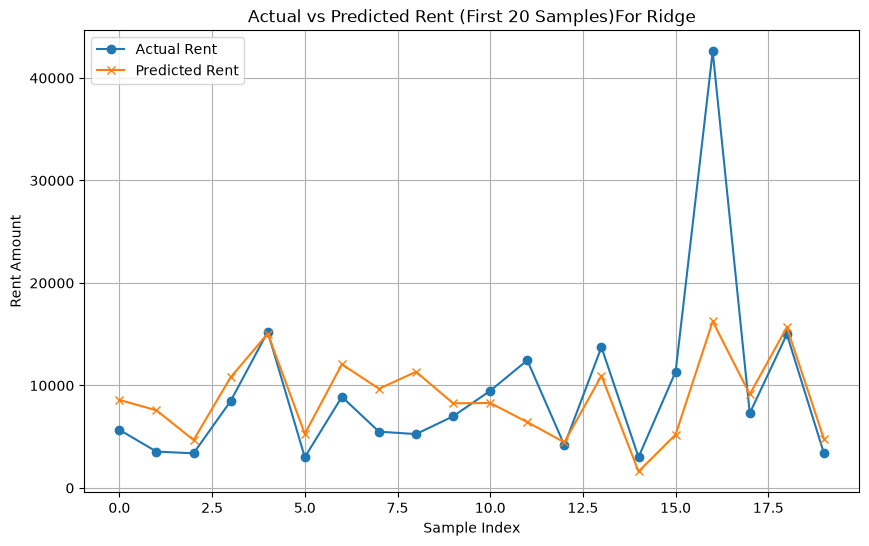

 21%|██▏       | 3/14 [00:00<00:02,  5.06it/s]

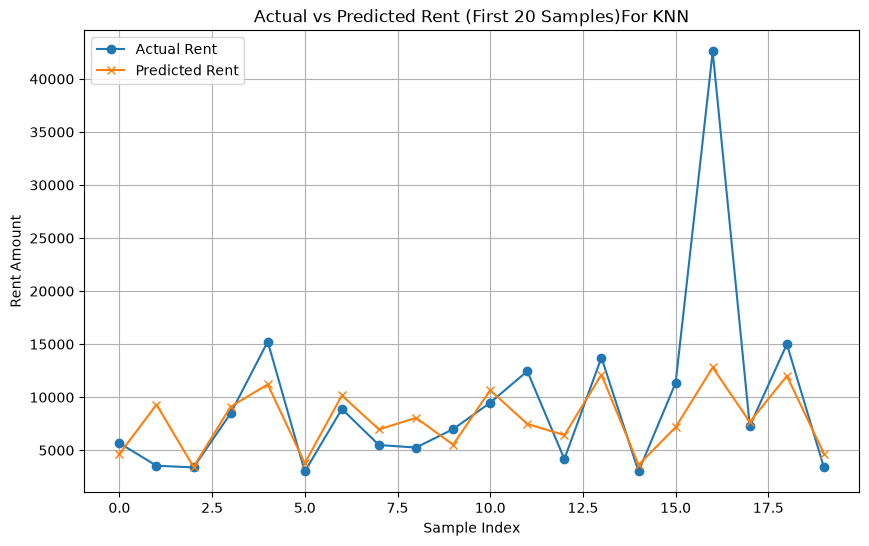

 29%|██▊       | 4/14 [00:00<00:01,  5.21it/s]

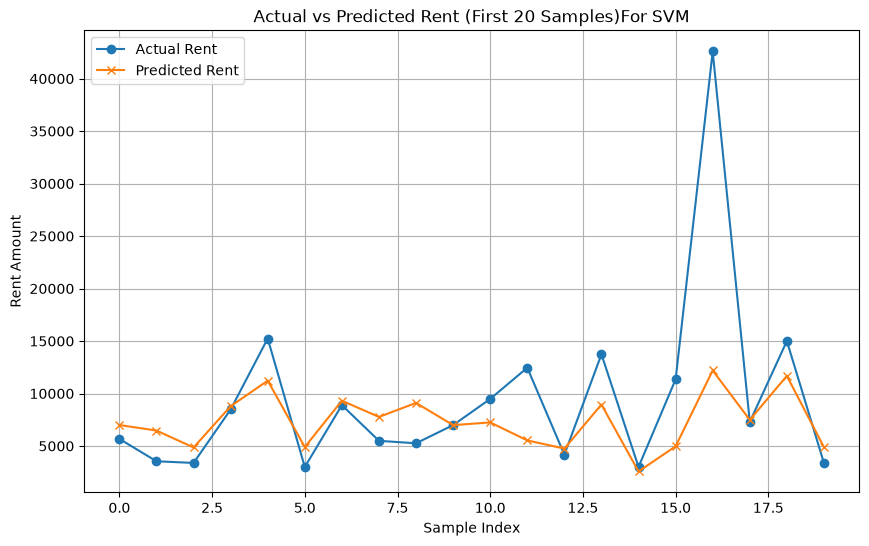

 36%|███▌      | 5/14 [00:00<00:01,  5.16it/s]

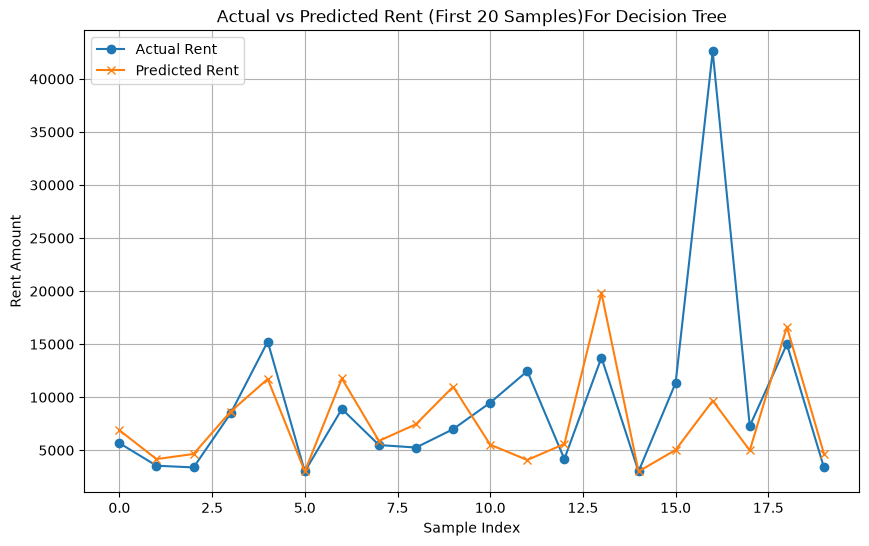

 43%|████▎     | 6/14 [00:01<00:01,  5.36it/s]

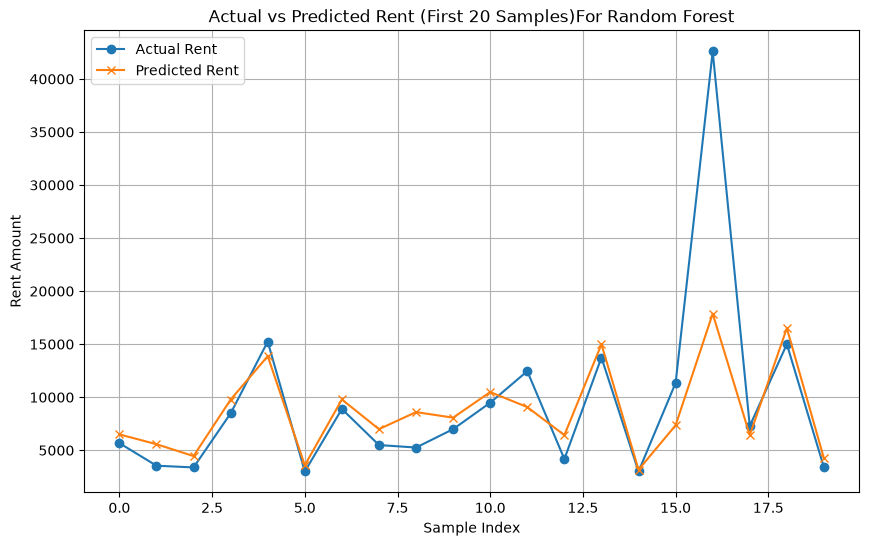

 50%|█████     | 7/14 [00:01<00:01,  4.52it/s]

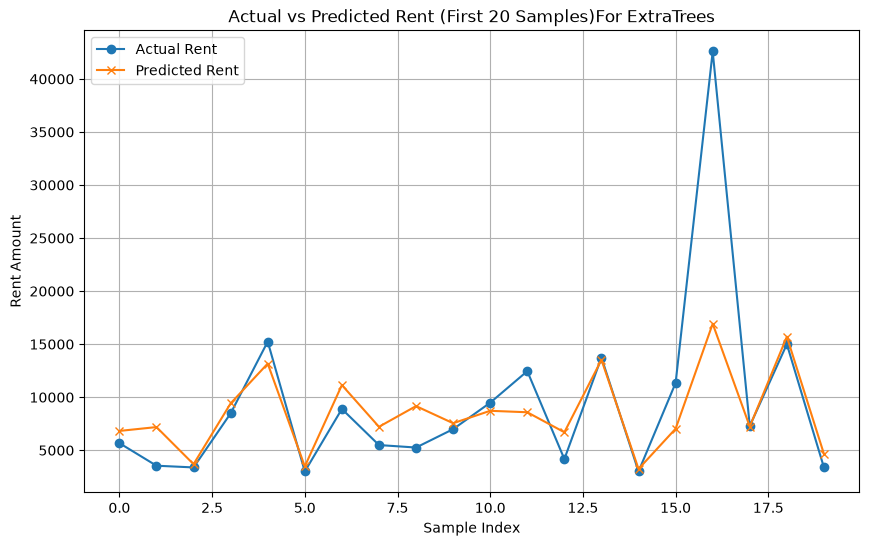

 57%|█████▋    | 8/14 [00:01<00:01,  3.46it/s]

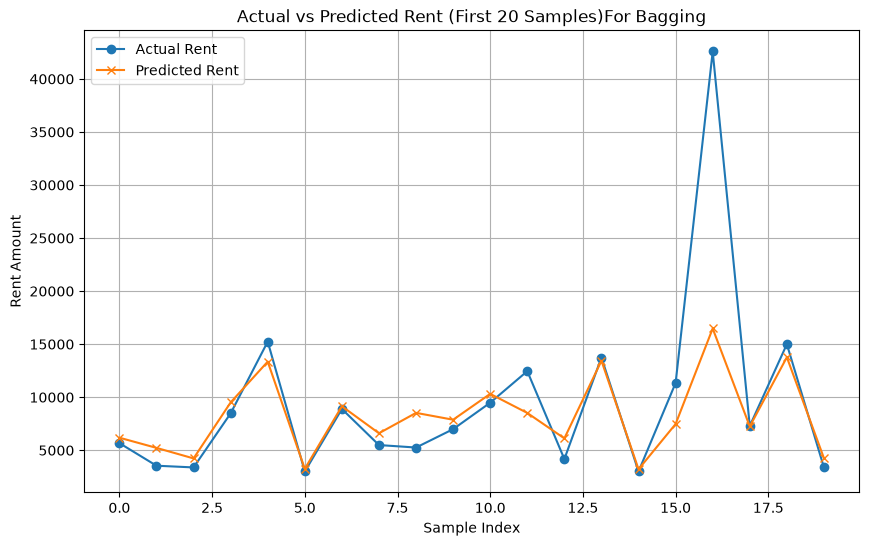

 64%|██████▍   | 9/14 [00:02<00:01,  3.38it/s]

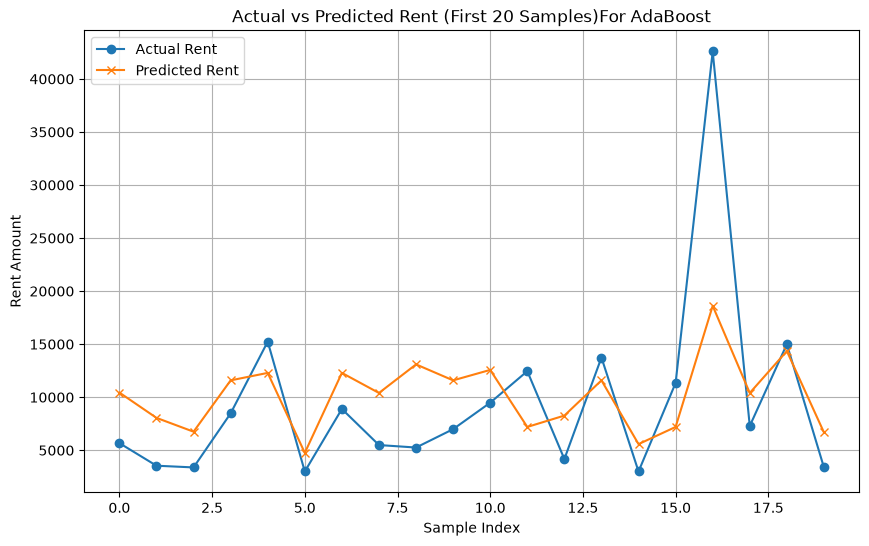

 71%|███████▏  | 10/14 [00:02<00:01,  3.75it/s]

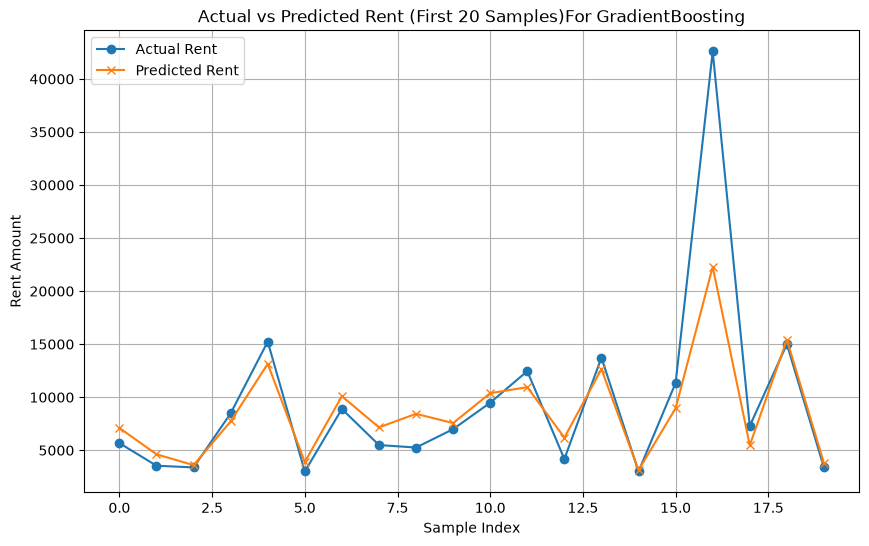

 79%|███████▊  | 11/14 [00:02<00:00,  3.65it/s]

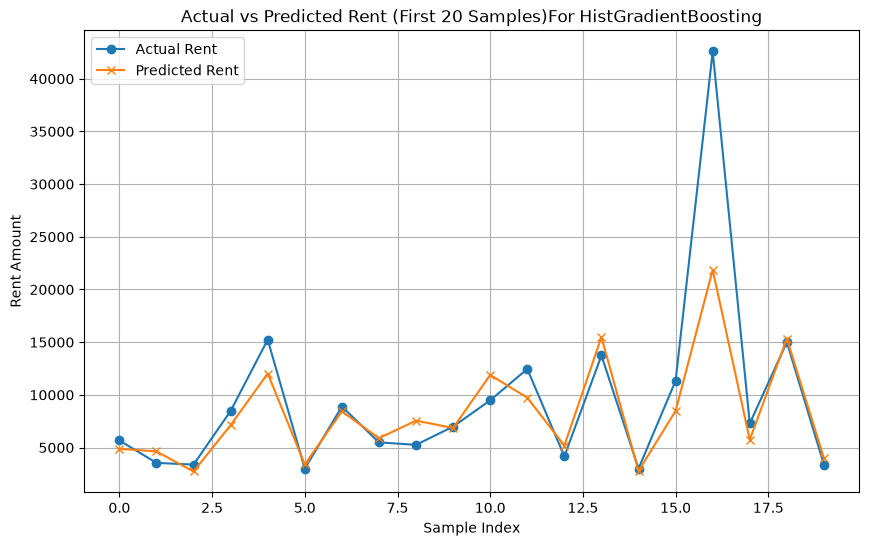

 86%|████████▌ | 12/14 [00:03<00:00,  3.28it/s]

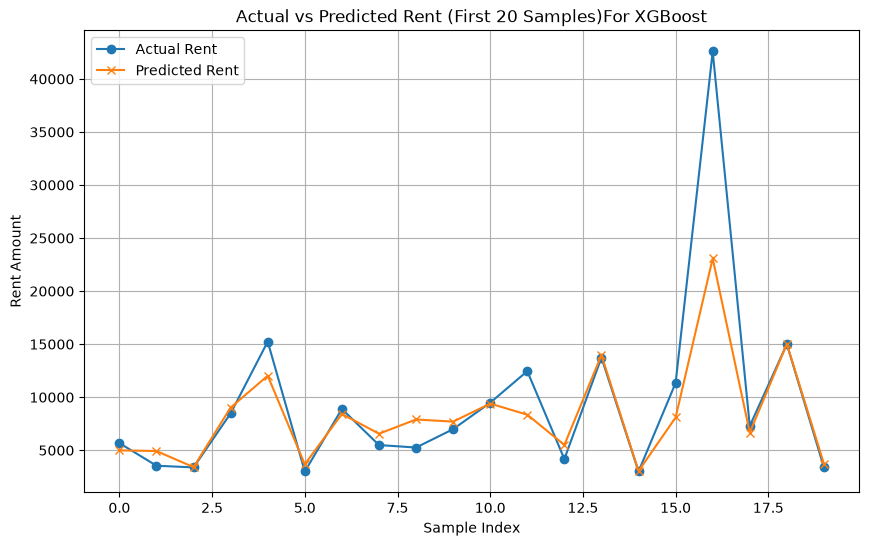

 93%|█████████▎| 13/14 [00:03<00:00,  3.21it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000121 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 326
[LightGBM] [Info] Number of data points in the train set: 800, number of used features: 9
[LightGBM] [Info] Start training from score 8463.016250
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

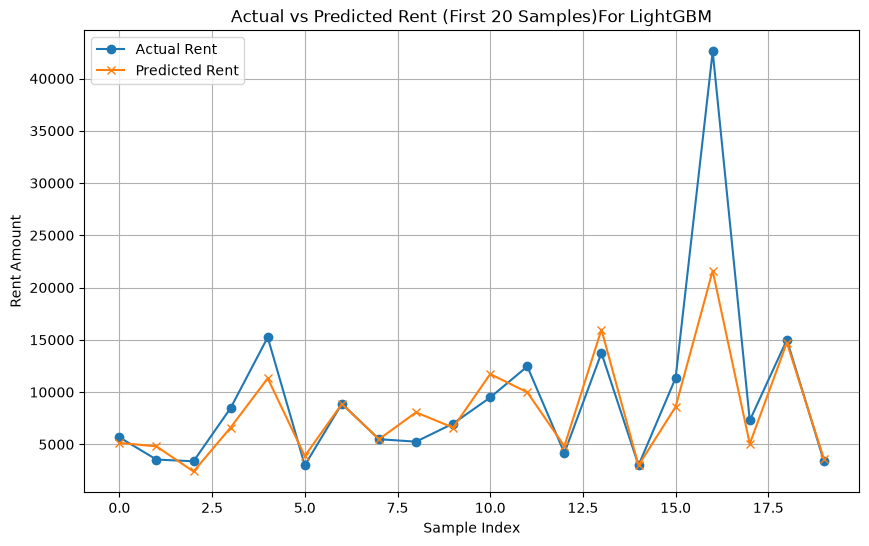

100%|██████████| 14/14 [00:03<00:00,  3.89it/s]


In [64]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [65]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [67]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    #('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [68]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [69]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
HistGradientBoosting,692.164595,1666.570525,1.799576e+06,8.819478e+06,1341.482743,2969.760615,0.953950,0.778079
Stacking,1037.139764,1717.880492,4.088792e+06,9.233201e+06,2022.076246,3038.618290,0.895369,0.772274
LightGBM,698.952870,1717.880492,1.782193e+06,9.233201e+06,1334.987905,3038.618290,0.954394,0.767669
GradientBoosting,1137.620579,1794.722539,3.288985e+06,9.246518e+06,1813.555904,3040.808839,0.915836,0.767333
XGBoost,309.803073,1844.023572,3.653965e+05,1.034310e+07,604.480389,3216.068997,0.990650,0.739741
Random Forest,846.919947,2173.773482,1.939574e+06,1.320345e+07,1392.685897,3633.655549,0.950367,0.667767
Bagging,801.243692,2116.801950,1.758798e+06,1.371444e+07,1326.196959,3703.301353,0.954993,0.654909
ExtraTrees,0.000000,2187.113250,0.000000e+00,1.426364e+07,0.000000,3776.723704,1.000000,0.641090
KNN,1918.730000,2225.119000,9.549868e+06,1.444484e+07,3090.286010,3800.636910,0.755623,0.636530
Voting,1259.777337,1717.880492,3.256254e+06,9.233201e+06,1804.509426,3038.618290,0.916674,0.589279


<Axes: >

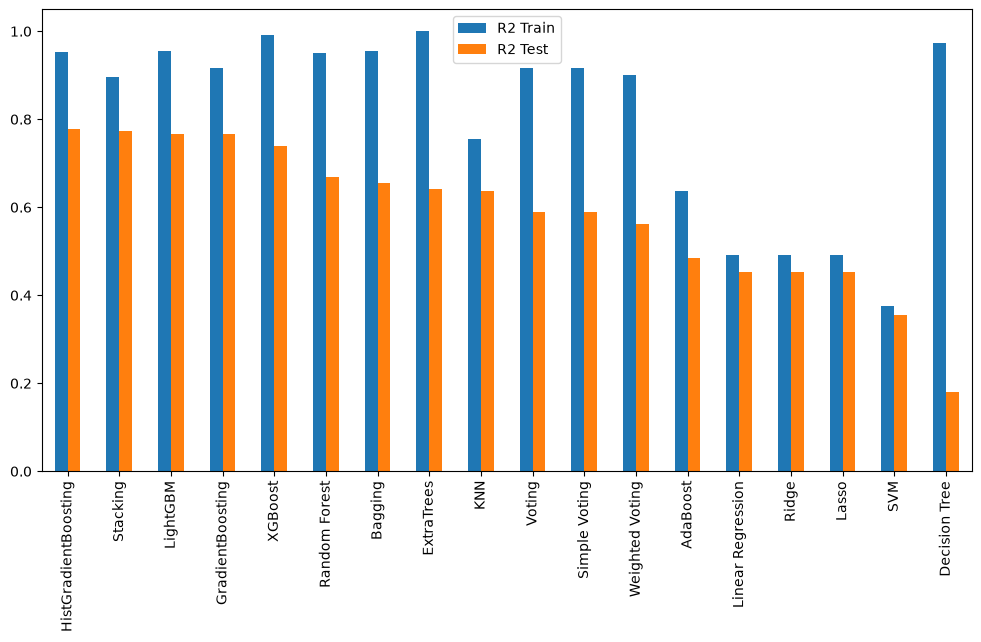

In [70]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

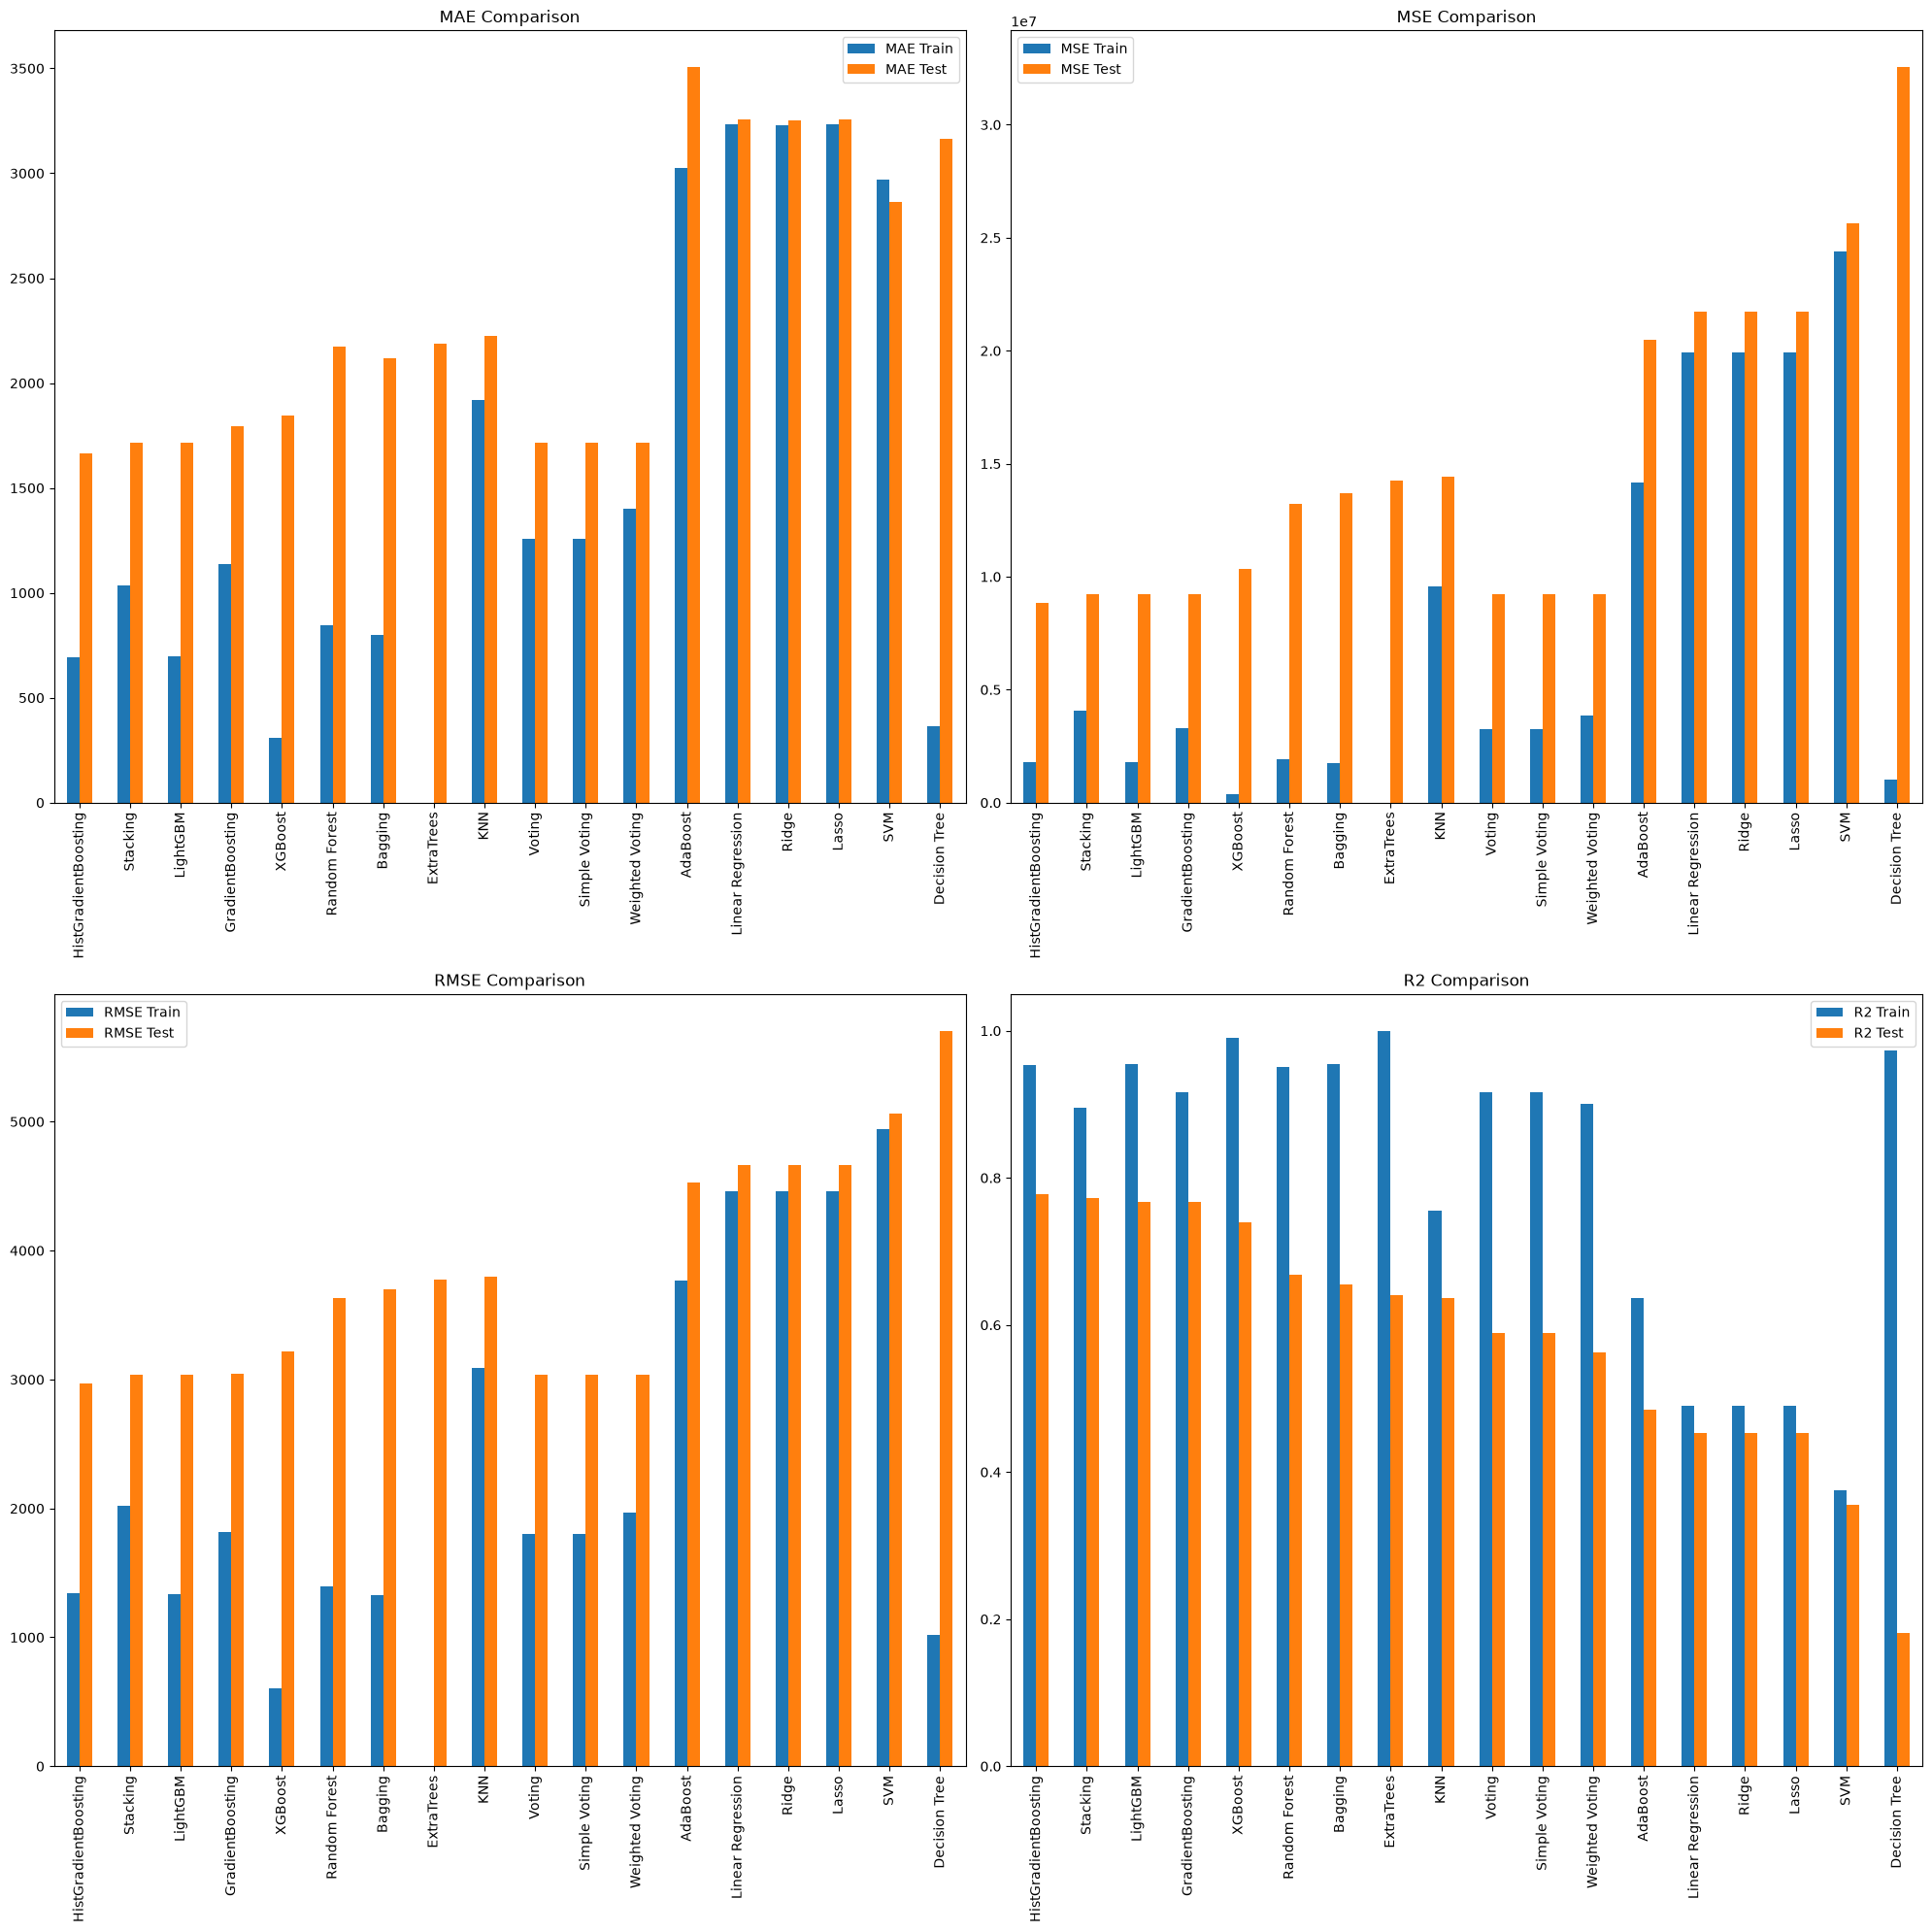

In [71]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()